<a href="https://colab.research.google.com/github/sats-11/sats-11-web-projects/blob/main/Emotion_%26_Mental_Health_detection_TF_ID.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

BASE_DIR = "/content/drive/MyDrive/Mental_Health_AI"

folders = [
    "data",
    "models",
    "results",
    "notebooks"
]

for folder in folders:
    os.makedirs(os.path.join(BASE_DIR, folder), exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [ ]:
for root, dirs, files in os.walk(BASE_DIR):
    level = root.replace(BASE_DIR, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

Mental_Health_AI/
    data/
        .ipynb_checkpoints/
    models/
    results/
    notebooks/


In [ ]:
import pandas as pd

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving emotion_dataset_raw.csv to emotion_dataset_raw.csv


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Combined Data-Sentiment Analysis for Mental Health.csv to Combined Data-Sentiment Analysis for Mental Health.csv


In [ ]:
import os

os.listdir('/content')

['.config',
 'Combined Data-Sentiment Analysis for Mental Health.csv',
 'drive',
 'emotion_dataset_raw.csv',
 'sample_data']

In [ ]:
import os

print("Files currently in /content:")
for file in os.listdir('/content'):
    print(repr(file))

Files currently in /content:
'.config'
'Combined Data-Sentiment Analysis for Mental Health.csv'
'drive'
'emotion_dataset_raw.csv'
'sample_data'


In [ ]:
import pandas as pd

emotion_df = pd.read_csv('/content/emotion_dataset_raw.csv')
mental_df = pd.read_csv('/content/Combined Data-Sentiment Analysis for Mental Health.csv')

print("Both datasets loaded successfully!")

Both datasets loaded successfully!


In [ ]:
print("EMOTION DATASET")
print("Rows:", emotion_df.shape[0])
print("Columns:", emotion_df.shape[1])

print("\nMENTAL HEALTH DATASET")
print("Rows:", mental_df.shape[0])
print("Columns:", mental_df.shape[1])

EMOTION DATASET
Rows: 34792
Columns: 2

MENTAL HEALTH DATASET
Rows: 53043
Columns: 3


In [ ]:
print("Emotion dataset columns:")
print(emotion_df.columns.tolist())

print("\nMental health dataset columns:")
print(mental_df.columns.tolist())

Emotion dataset columns:
['Emotion', 'Text']

Mental health dataset columns:
['Unnamed: 0', 'statement', 'status']


In [ ]:
!pip install nltk

In [ ]:
import re
import nltk
import pandas as pd

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download required resources
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [ ]:
# ============================================
# NEGATION-AWARE NLP PREPROCESSING
# ============================================

stop_words = set(stopwords.words('english'))

# Keep words that can change the meaning of a sentence
negation_words = {
    "no",
    "not",
    "nor",
    "never",
    "cannot",
    "can't",
    "couldn't",
    "don't",
    "doesn't",
    "didn't",
    "isn't",
    "aren't",
    "wasn't",
    "weren't",
    "won't",
    "wouldn't",
    "shouldn't",
    "haven't",
    "hasn't",
    "hadn't",
    "mustn't"
}

# Remove negation words from the stop-word list
stop_words = stop_words - negation_words

# Lemmatizer
lemmatizer = WordNetLemmatizer()


def preprocess_text(text):

    # ----------------------------------------
    # 1. Convert to string
    # ----------------------------------------
    text = str(text)

    # ----------------------------------------
    # 2. Lowercase
    # ----------------------------------------
    text = text.lower()

    # ----------------------------------------
    # 3. Handle common contractions
    # ----------------------------------------
    contractions = {
        "can't": "cannot",
        "won't": "will not",
        "don't": "do not",
        "doesn't": "does not",
        "didn't": "did not",
        "isn't": "is not",
        "aren't": "are not",
        "wasn't": "was not",
        "weren't": "were not",
        "haven't": "have not",
        "hasn't": "has not",
        "hadn't": "had not",
        "couldn't": "could not",
        "wouldn't": "would not",
        "shouldn't": "should not",
        "mustn't": "must not"
    }

    for contraction, expanded in contractions.items():
        text = text.replace(contraction, expanded)

    # ----------------------------------------
    # 4. Remove URLs
    # ----------------------------------------
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # ----------------------------------------
    # 5. Remove @mentions
    # ----------------------------------------
    text = re.sub(r'@\w+', ' ', text)

    # ----------------------------------------
    # 6. Remove extra characters
    # Keep only letters and spaces
    # ----------------------------------------
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)

    # ----------------------------------------
    # 7. Remove extra spaces
    # ----------------------------------------
    text = re.sub(r'\s+', ' ', text).strip()

    # ----------------------------------------
    # 8. Tokenization
    # ----------------------------------------
    tokens = word_tokenize(text)

    # ----------------------------------------
    # 9. Stop-word removal
    #    + Lemmatization
    # ----------------------------------------
    processed_tokens = []

    for word in tokens:

        if word not in stop_words:

            lemma = lemmatizer.lemmatize(word)

            processed_tokens.append(lemma)

    # ----------------------------------------
    # 10. Return processed sentence
    # ----------------------------------------
    return " ".join(processed_tokens)

In [ ]:
test_text = """
I don't feel happy anymore.
I am not sleeping properly and I can't stop worrying.
"""

print("ORIGINAL:")
print(test_text)

print("\nPROCESSED:")
print(preprocess_text(test_text))

ORIGINAL:

I don't feel happy anymore.
I am not sleeping properly and I can't stop worrying.


PROCESSED:
not feel happy anymore not sleeping properly not stop worrying


In [ ]:
# ============================================
# EMOTION DATASET
# ============================================

emotion_df["Processed_Text"] = (
    emotion_df["Text"]
    .fillna("")
    .apply(preprocess_text)
)

display(
    emotion_df[
        ["Text", "Processed_Text"]
    ].head(10)
)

,Text,Processed_Text
0,Why ?,
1,Sage Act upgrade on my to do list for tommorow.,sage act upgrade list tommorow
2,ON THE WAY TO MY HOMEGIRL BABY FUNERAL!!! MAN ...,way homegirl baby funeral man hate funeral rea...
3,Such an eye ! The true hazel eye-and so brill...,eye true hazel eye brilliant regular feature o...
4,@Iluvmiasantos ugh babe.. hugggzzz for u .! b...,ugh babe hugggzzz u babe naamazed nga ako e ba...
5,I'm expecting an extremely important phonecall...,expecting extremely important phonecall minute...
6,.Couldnt wait to see them live. If missing th...,couldnt wait see live missing nh wasnt painful...
7,maken Tip 2: Stop op een moment dat je het hel...,maken tip stop op een moment dat je het hele p...
8,En dan krijg je ff een cadeautje van een tweep...,en dan krijg je ff een cadeautje van een tweep...
9,@1116am Drummer Boy bij op verzoek van @BiemO...,drummer boy bij op verzoek van welke uitvoerin...


In [ ]:
# ============================================
# MENTAL HEALTH DATASET
# ============================================

mental_df["Processed_Text"] = (
    mental_df["statement"]
    .fillna("")
    .apply(preprocess_text)
)

display(
    mental_df[
        ["statement", "Processed_Text"]
    ].head(10)
)

,statement,Processed_Text
0,oh my gosh,oh gosh
1,"trouble sleeping, confused mind, restless hear...",trouble sleeping confused mind restless heart ...
2,"All wrong, back off dear, forward doubt. Stay ...",wrong back dear forward doubt stay restless re...
3,I've shifted my focus to something else but I'...,shifted focus something else still worried
4,"I'm restless and restless, it's been a month n...",restless restless month boy mean
5,"every break, you must be nervous, like somethi...",every break must nervous like something wrong ...
6,"I feel scared, anxious, what can I do? And may...",feel scared anxious may family u protected
7,Have you ever felt nervous but didn't know why?,ever felt nervous not know
8,"I haven't slept well for 2 days, it's like I'm...",not slept well day like restless huh
9,"I'm really worried, I want to cry.",really worried want cry


In [ ]:
print("EMOTION DATASET")
display(emotion_df.head())

print("\nMENTAL HEALTH DATASET")
display(mental_df.head())

EMOTION DATASET


,Emotion,Text,Processed_Text
0,neutral,Why ?,
1,joy,Sage Act upgrade on my to do list for tommorow.,sage act upgrade list tommorow
2,sadness,ON THE WAY TO MY HOMEGIRL BABY FUNERAL!!! MAN ...,way homegirl baby funeral man hate funeral rea...
3,joy,Such an eye ! The true hazel eye-and so brill...,eye true hazel eye brilliant regular feature o...
4,joy,@Iluvmiasantos ugh babe.. hugggzzz for u .! b...,ugh babe hugggzzz u babe naamazed nga ako e ba...



MENTAL HEALTH DATASET


,Unnamed: 0,statement,status,Processed_Text
0,0,oh my gosh,Anxiety,oh gosh
1,1,"trouble sleeping, confused mind, restless hear...",Anxiety,trouble sleeping confused mind restless heart ...
2,2,"All wrong, back off dear, forward doubt. Stay ...",Anxiety,wrong back dear forward doubt stay restless re...
3,3,I've shifted my focus to something else but I'...,Anxiety,shifted focus something else still worried
4,4,"I'm restless and restless, it's been a month n...",Anxiety,restless restless month boy mean


In [ ]:
print("=" * 60)
print("EMOTION DATASET")
print("=" * 60)

print("\n1. Dataset shape:")
print(emotion_df.shape)

print("\n2. Missing values:")
print(emotion_df.isnull().sum())

print("\n3. Duplicate rows:")
print(emotion_df.duplicated().sum())

print("\n4. Emotion class distribution:")
print(emotion_df['Emotion'].value_counts())

print("\n" + "=" * 60)
print("MENTAL HEALTH DATASET")
print("=" * 60)

print("\n1. Dataset shape:")
print(mental_df.shape)

print("\n2. Missing values:")
print(mental_df.isnull().sum())

print("\n3. Duplicate rows:")
print(mental_df.duplicated().sum())

print("\n4. Mental health class distribution:")
print(mental_df['status'].value_counts())

EMOTION DATASET

1. Dataset shape:
(34792, 3)

2. Missing values:
Emotion           0
Text              0
Processed_Text    0
dtype: int64

3. Duplicate rows:
3630

4. Emotion class distribution:
Emotion
joy         11045
sadness      6722
fear         5410
anger        4297
surprise     4062
neutral      2254
disgust       856
shame         146
Name: count, dtype: int64

MENTAL HEALTH DATASET

1. Dataset shape:
(53043, 4)

2. Missing values:
Unnamed: 0          0
statement         362
status              0
Processed_Text      0
dtype: int64

3. Duplicate rows:
0

4. Mental health class distribution:
status
Normal                  16351
Depression              15404
Suicidal                10653
Anxiety                  3888
Bipolar                  2877
Stress                   2669
Personality disorder     1201
Name: count, dtype: int64


In [ ]:
print("=" * 60)
print("EMOTION TEXT EXAMPLES")
print("=" * 60)

for i in range(10):
    print(f"\n{i+1}.")
    print("Emotion:", emotion_df.iloc[i]['Emotion'])
    print("Text:", emotion_df.iloc[i]['Text'])


print("\n" + "=" * 60)
print("MENTAL HEALTH TEXT EXAMPLES")
print("=" * 60)

for i in range(10):
    print(f"\n{i+1}.")
    print("Status:", mental_df.iloc[i]['status'])
    print("Text:", mental_df.iloc[i]['statement'])

EMOTION TEXT EXAMPLES

1.
Emotion: neutral
Text:  Why ? 

2.
Emotion: joy
Text: Sage Act upgrade on my to do list for tommorow.

3.
Emotion: sadness
Text: ON THE WAY TO MY HOMEGIRL BABY FUNERAL!!! MAN I HATE FUNERALS THIS REALLY SHOWS ME HOW BLESSED I AM 

4.
Emotion: joy
Text:  Such an eye ! The true hazel eye-and so brilliant ! Regular features , open countenance , with a complexion , Oh ! What a bloom of full health , and such a pretty height and size ; such a firm and upright figure ! There is health , not merely in her bloom , but in her air , her head , her glance . One hears sometimes of a child being ' the picture of health ' ; now , she always gives me the idea of being the complete picture of grown-up health . She is loveliness itself . 

5.
Emotion: joy
Text: @Iluvmiasantos ugh babe.. hugggzzz for u .!  babe naamazed nga ako e babe e, despite nega's mas pinaramdam at fil ko ang 

6.
Emotion: fear
Text: I'm expecting an extremely important phonecall any minute now #terror #op

In [ ]:
print("Emotion empty texts:")
print((emotion_df['Text'].fillna('').str.strip() == '').sum())

print("\nMental-health empty texts:")
print((mental_df['statement'].fillna('').str.strip() == '').sum())


Emotion empty texts:
0

Mental-health empty texts:
362


In [ ]:
print("Emotion duplicate texts:")
print(emotion_df['Text'].duplicated().sum())

print("\nMental-health duplicate statements:")
print(mental_df['statement'].duplicated().sum())

Emotion duplicate texts:
3682

Mental-health duplicate statements:
1969


In [ ]:
emotion_conflicts = (
    emotion_df.groupby('Text')['Emotion']
    .nunique()
    .sort_values(ascending=False)
)

print("Emotion texts having multiple labels:")
print(emotion_conflicts[emotion_conflicts > 1].head(20))

Emotion texts having multiple labels:
Text
 Why not ?                                                                                                       3
 See you .                                                                                                       3
 Sure .                                                                                                          2
 No .                                                                                                            2
 I'm sorry .                                                                                                     2
 Certainly not .                                                                                                 2
 It's us .                                                                                                       2
 You often like comparing children with their parents .                                                          2
 Okay .                              

In [ ]:
mental_conflicts = (
    mental_df.groupby('statement')['status']
    .nunique()
    .sort_values(ascending=False)
)

print("Mental-health statements having multiple labels:")
print(mental_conflicts[mental_conflicts > 1].head(20))

Mental-health statements having multiple labels:
statement
#NAME?                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                       

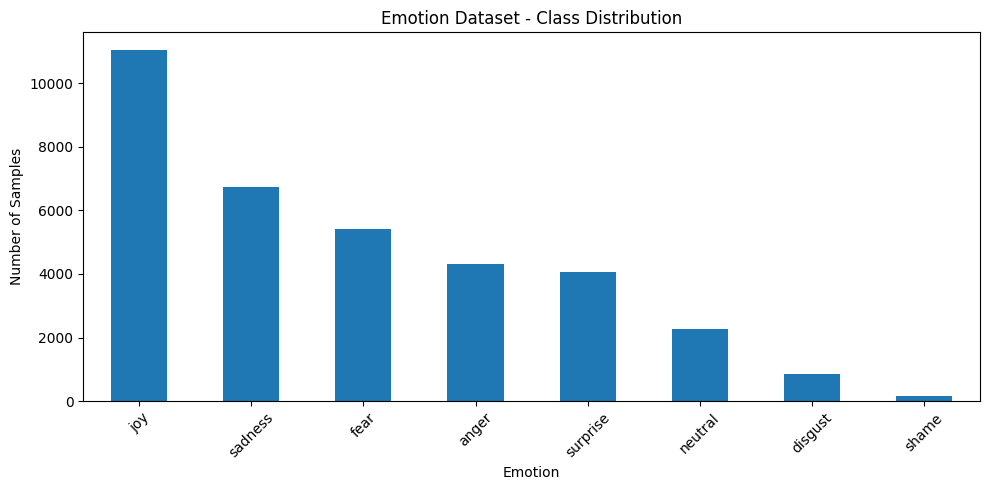

In [ ]:
import matplotlib.pyplot as plt

emotion_counts = emotion_df['Emotion'].value_counts()

plt.figure(figsize=(10, 5))
emotion_counts.plot(kind='bar')
plt.title('Emotion Dataset - Class Distribution')
plt.xlabel('Emotion')
plt.ylabel('Number of Samples')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

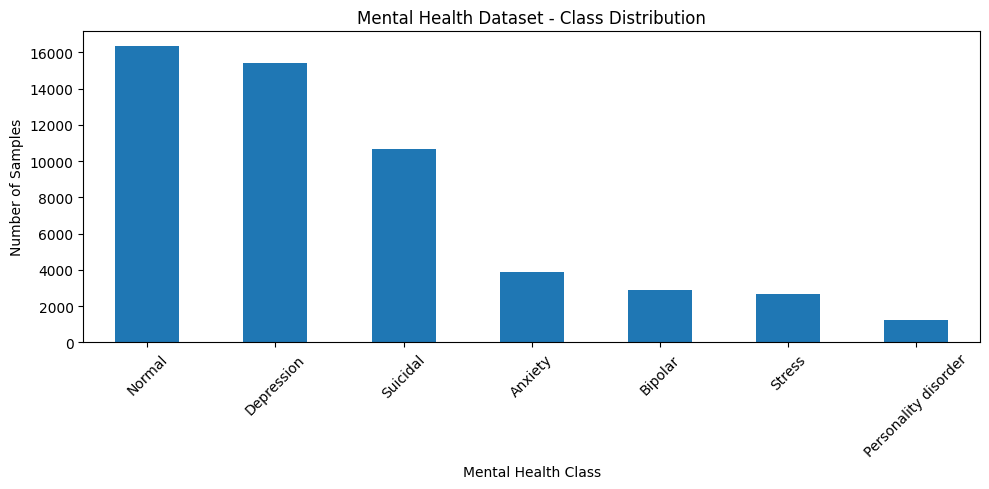

In [ ]:
mental_counts = mental_df['status'].value_counts()

plt.figure(figsize=(10, 5))
mental_counts.plot(kind='bar')
plt.title('Mental Health Dataset - Class Distribution')
plt.xlabel('Mental Health Class')
plt.ylabel('Number of Samples')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Find texts that have more than one emotion label
emotion_conflict_counts = (
    emotion_df.groupby('Text')['Emotion']
    .nunique()
)

conflicting_emotion_texts = emotion_conflict_counts[
    emotion_conflict_counts > 1
]

print("Number of texts with conflicting emotion labels:",
      len(conflicting_emotion_texts))

Number of texts with conflicting emotion labels: 50


In [ ]:
# Show some actual conflicts
conflict_examples = (
    emotion_df[emotion_df['Text'].isin(conflicting_emotion_texts.index)]
    .sort_values('Text')
)

display(conflict_examples.head(30))

,Emotion,Text,Processed_Text
25814,neutral,All right .,right
12753,neutral,All right .,right
32847,neutral,All right .,right
12131,neutral,All right .,right
1866,joy,All right .,right
9189,neutral,All right .,right
19948,neutral,All right .,right
14623,neutral,All right .,right
19292,neutral,And why are you yarning now ? Are you bored ?,yarning bored
1401,anger,And why are you yarning now ? Are you bored ?,yarning bored


In [ ]:
mental_conflict_counts = (
    mental_df.groupby('statement')['status']
    .nunique()
)

mental_conflicting = mental_conflict_counts[
    mental_conflict_counts > 1
]

print("Mental-health statements with conflicting labels:",
      len(mental_conflicting))

Mental-health statements with conflicting labels: 18


In [ ]:
mental_conflict_examples = (
    mental_df[
        mental_df['statement'].isin(mental_conflicting.index)
    ]
    .sort_values('statement')
)

display(mental_conflict_examples.head(20))

,Unnamed: 0,statement,status,Processed_Text
28938,28938,#NAME?,Stress,name
23605,23605,#NAME?,Depression,name
20955,20955,#NAME?,Depression,name
20464,20464,#NAME?,Suicidal,name
19786,19786,#NAME?,Depression,name
18196,18196,#NAME?,Depression,name
23743,23743,#NAME?,Depression,name
27641,27641,#NAME?,Normal,name
22694,22694,#NAME?,Depression,name
29536,29536,#NAME?,Stress,name


In [ ]:
mental_duplicate_groups = (
    mental_df.groupby('statement')['status']
    .agg(['count', 'nunique'])
)

same_label_duplicates = mental_duplicate_groups[
    (mental_duplicate_groups['count'] > 1) &
    (mental_duplicate_groups['nunique'] == 1)
]

print("Repeated statements with the SAME label:",
      len(same_label_duplicates))

print("Repeated statements with DIFFERENT labels:",
      len(mental_conflicting))

Repeated statements with the SAME label: 1385
Repeated statements with DIFFERENT labels: 18


In [ ]:
# ============================================================
# STEP 4 — CLEAN DATASETS
# ============================================================

# Make copies
emotion_clean = emotion_df.copy()
mental_clean = mental_df.copy()

# ============================================================
# A. EMOTION DATASET
# ============================================================

print("Original Emotion Dataset:", emotion_clean.shape)

# Remove missing text
emotion_clean = emotion_clean.dropna(subset=['Text'])

# Clean whitespace
emotion_clean['Text'] = emotion_clean['Text'].astype(str).str.strip()

# Find texts with conflicting emotion labels
emotion_label_counts = (
    emotion_clean.groupby('Text')['Emotion']
    .nunique()
)

conflicting_emotion_texts = emotion_label_counts[
    emotion_label_counts > 1
].index

print(
    "Conflicting emotion texts:",
    len(conflicting_emotion_texts)
)

# Remove conflicting texts
emotion_clean = emotion_clean[
    ~emotion_clean['Text'].isin(conflicting_emotion_texts)
]

# Remove duplicate rows
emotion_clean = emotion_clean.drop_duplicates()

# Remove duplicate texts
emotion_clean = emotion_clean.drop_duplicates(
    subset=['Text'],
    keep='first'
)

# Reset index
emotion_clean = emotion_clean.reset_index(drop=True)

print("Clean Emotion Dataset:", emotion_clean.shape)


# ============================================================
# B. MENTAL-HEALTH DATASET
# ============================================================

print("\nOriginal Mental Health Dataset:", mental_clean.shape)

# Remove unnecessary index column
mental_clean = mental_clean.drop(
    columns=['Unnamed: 0'],
    errors='ignore'
)

# Remove missing statements
mental_clean = mental_clean.dropna(
    subset=['statement']
)

# Convert to string and remove whitespace
mental_clean['statement'] = (
    mental_clean['statement']
    .astype(str)
    .str.strip()
)

# Remove empty statements
mental_clean = mental_clean[
    mental_clean['statement'] != ''
]

# Find statements with conflicting labels
mental_label_counts = (
    mental_clean.groupby('statement')['status']
    .nunique()
)

conflicting_mental_statements = mental_label_counts[
    mental_label_counts > 1
].index

print(
    "Conflicting mental-health statements:",
    len(conflicting_mental_statements)
)

# Remove conflicting statements
mental_clean = mental_clean[
    ~mental_clean['statement'].isin(
        conflicting_mental_statements
    )
]

# Remove duplicate statements
mental_clean = mental_clean.drop_duplicates(
    subset=['statement'],
    keep='first'
)

# Reset index
mental_clean = mental_clean.reset_index(drop=True)

print("Clean Mental Health Dataset:", mental_clean.shape)

Original Emotion Dataset: (34792, 3)
Conflicting emotion texts: 51
Clean Emotion Dataset: (31043, 3)

Original Mental Health Dataset: (53043, 4)
Conflicting mental-health statements: 18
Clean Mental Health Dataset: (51055, 3)


In [ ]:
print("=" * 60)
print("CLEANED DATASET CHECK")
print("=" * 60)

print("\nEmotion dataset:")
print("Shape:", emotion_clean.shape)
print("Missing values:")
print(emotion_clean.isnull().sum())
print("Duplicate texts:",
      emotion_clean['Text'].duplicated().sum())

print("\nEmotion classes:")
print(emotion_clean['Emotion'].value_counts())


print("\nMental-health dataset:")
print("Shape:", mental_clean.shape)
print("Missing values:")
print(mental_clean.isnull().sum())
print("Duplicate statements:",
      mental_clean['statement'].duplicated().sum())

print("\nMental-health classes:")
print(mental_clean['status'].value_counts())

CLEANED DATASET CHECK

Emotion dataset:
Shape: (31043, 3)
Missing values:
Emotion           0
Text              0
Processed_Text    0
dtype: int64
Duplicate texts: 0

Emotion classes:
Emotion
joy         10439
sadness      6158
fear         4251
surprise     4015
anger        3764
neutral      1417
disgust       855
shame         144
Name: count, dtype: int64

Mental-health dataset:
Shape: (51055, 3)
Missing values:
statement         0
status            0
Processed_Text    0
dtype: int64
Duplicate statements: 0

Mental-health classes:
status
Normal                  16037
Depression              15078
Suicidal                10634
Anxiety                  3617
Bipolar                  2501
Stress                   2293
Personality disorder      895
Name: count, dtype: int64


In [ ]:
# Emotion conflicts after cleaning
emotion_remaining_conflicts = (
    emotion_clean.groupby('Text')['Emotion']
    .nunique()
)

print(
    "Remaining emotion conflicts:",
    (emotion_remaining_conflicts > 1).sum()
)


# Mental-health conflicts after cleaning
mental_remaining_conflicts = (
    mental_clean.groupby('statement')['status']
    .nunique()
)

print(
    "Remaining mental-health conflicts:",
    (mental_remaining_conflicts > 1).sum()
)

Remaining emotion conflicts: 0
Remaining mental-health conflicts: 0


In [ ]:
print(
    "Number of #NAME? statements:",
    (mental_clean['statement'] == '#NAME?').sum()
)

Number of #NAME? statements: 0


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
# ============================================
# EMOTION DATASET SPLIT
# ============================================

X_emotion = emotion_clean['Text']
y_emotion = emotion_clean['Emotion']

# First: 80% train, 20% temporary
X_emotion_train, X_emotion_temp, y_emotion_train, y_emotion_temp = train_test_split(
    X_emotion,
    y_emotion,
    test_size=0.20,
    random_state=42,
    stratify=y_emotion
)

# Second: split the temporary 20% into
# 10% validation + 10% test
X_emotion_val, X_emotion_test, y_emotion_val, y_emotion_test = train_test_split(
    X_emotion_temp,
    y_emotion_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_emotion_temp
)

print("EMOTION DATASET")
print("----------------")
print("Training:", len(X_emotion_train))
print("Validation:", len(X_emotion_val))
print("Testing:", len(X_emotion_test))

EMOTION DATASET
----------------
Training: 24834
Validation: 3104
Testing: 3105


In [ ]:
print("TRAINING")
print(y_emotion_train.value_counts())

print("\nVALIDATION")
print(y_emotion_val.value_counts())

print("\nTEST")
print(y_emotion_test.value_counts())

TRAINING
Emotion
joy         8351
sadness     4926
fear        3401
surprise    3212
anger       3011
neutral     1134
disgust      684
shame        115
Name: count, dtype: int64

VALIDATION
Emotion
joy         1044
sadness      616
fear         425
surprise     401
anger        376
neutral      141
disgust       86
shame         15
Name: count, dtype: int64

TEST
Emotion
joy         1044
sadness      616
fear         425
surprise     402
anger        377
neutral      142
disgust       85
shame         14
Name: count, dtype: int64


In [ ]:
# ============================================
# MENTAL HEALTH DATASET SPLIT
# ============================================

X_mental = mental_clean['statement']
y_mental = mental_clean['status']

# First: 80% train, 20% temporary
X_mental_train, X_mental_temp, y_mental_train, y_mental_temp = train_test_split(
    X_mental,
    y_mental,
    test_size=0.20,
    random_state=42,
    stratify=y_mental
)

# Second: 10% validation, 10% test
X_mental_val, X_mental_test, y_mental_val, y_mental_test = train_test_split(
    X_mental_temp,
    y_mental_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_mental_temp
)

print("MENTAL HEALTH DATASET")
print("---------------------")
print("Training:", len(X_mental_train))
print("Validation:", len(X_mental_val))
print("Testing:", len(X_mental_test))

MENTAL HEALTH DATASET
---------------------
Training: 40844
Validation: 5105
Testing: 5106


In [ ]:
print("TRAINING")
print(y_mental_train.value_counts())

print("\nVALIDATION")
print(y_mental_val.value_counts())

print("\nTEST")
print(y_mental_test.value_counts())

TRAINING
status
Normal                  12830
Depression              12062
Suicidal                 8507
Anxiety                  2894
Bipolar                  2001
Stress                   1834
Personality disorder      716
Name: count, dtype: int64

VALIDATION
status
Normal                  1603
Depression              1508
Suicidal                1063
Anxiety                  361
Bipolar                  250
Stress                   230
Personality disorder      90
Name: count, dtype: int64

TEST
status
Normal                  1604
Depression              1508
Suicidal                1064
Anxiety                  362
Bipolar                  250
Stress                   229
Personality disorder      89
Name: count, dtype: int64


In [ ]:
import os

os.makedirs('/content/results', exist_ok=True)

# Emotion
pd.DataFrame({
    'Text': X_emotion_train,
    'Emotion': y_emotion_train
}).to_csv('/content/results/emotion_train.csv', index=False)

pd.DataFrame({
    'Text': X_emotion_val,
    'Emotion': y_emotion_val
}).to_csv('/content/results/emotion_validation.csv', index=False)

pd.DataFrame({
    'Text': X_emotion_test,
    'Emotion': y_emotion_test
}).to_csv('/content/results/emotion_test.csv', index=False)


# Mental health
pd.DataFrame({
    'statement': X_mental_train,
    'status': y_mental_train
}).to_csv('/content/results/mental_train.csv', index=False)

pd.DataFrame({
    'statement': X_mental_val,
    'status': y_mental_val
}).to_csv('/content/results/mental_validation.csv', index=False)

pd.DataFrame({
    'statement': X_mental_test,
    'status': y_mental_test
}).to_csv('/content/results/mental_test.csv', index=False)

print("All six splits saved successfully!")

All six splits saved successfully!


In [ ]:
# ============================================
# STEP 6: BASELINE ML MODELS
# ============================================

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt

In [ ]:
# ============================================
# EMOTION MODEL — TF-IDF
# ============================================

emotion_vectorizer = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_emotion_train_tfidf = emotion_vectorizer.fit_transform(
    X_emotion_train
)

X_emotion_val_tfidf = emotion_vectorizer.transform(
    X_emotion_val
)

X_emotion_test_tfidf = emotion_vectorizer.transform(
    X_emotion_test
)

print("Emotion TF-IDF shape:")
print("Training:", X_emotion_train_tfidf.shape)
print("Validation:", X_emotion_val_tfidf.shape)
print("Testing:", X_emotion_test_tfidf.shape)

Emotion TF-IDF shape:
Training: (24834, 30000)
Validation: (3104, 30000)
Testing: (3105, 30000)


In [ ]:
emotion_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

emotion_model.fit(
    X_emotion_train_tfidf,
    y_emotion_train
)

print("Emotion model trained successfully!")

Emotion model trained successfully!


In [ ]:
emotion_val_pred = emotion_model.predict(
    X_emotion_val_tfidf
)

emotion_test_pred = emotion_model.predict(
    X_emotion_test_tfidf
)

In [ ]:
print("EMOTION MODEL — VALIDATION")
print("=" * 50)

print(
    "Accuracy:",
    accuracy_score(y_emotion_val, emotion_val_pred)
)

print(
    "Macro Precision:",
    precision_score(
        y_emotion_val,
        emotion_val_pred,
        average='macro'
    )
)

print(
    "Macro Recall:",
    recall_score(
        y_emotion_val,
        emotion_val_pred,
        average='macro'
    )
)

print(
    "Macro F1:",
    f1_score(
        y_emotion_val,
        emotion_val_pred,
        average='macro'
    )
)

EMOTION MODEL — VALIDATION
Accuracy: 0.5670103092783505
Macro Precision: 0.5426969593743862
Macro Recall: 0.6086913494460986
Macro F1: 0.5629523588755718


In [ ]:
print("\nEMOTION MODEL — TEST")
print("=" * 50)

print(
    "Accuracy:",
    accuracy_score(y_emotion_test, emotion_test_pred)
)

print(
    "Macro Precision:",
    precision_score(
        y_emotion_test,
        emotion_test_pred,
        average='macro'
    )
)

print(
    "Macro Recall:",
    recall_score(
        y_emotion_test,
        emotion_test_pred,
        average='macro'
    )
)

print(
    "Macro F1:",
    f1_score(
        y_emotion_test,
        emotion_test_pred,
        average='macro'
    )
)


EMOTION MODEL — TEST
Accuracy: 0.5710144927536231
Macro Precision: 0.5556547098084708
Macro Recall: 0.6277270274590553
Macro F1: 0.5782280002096174


In [ ]:
print(
    classification_report(
        y_emotion_test,
        emotion_test_pred
    )
)

              precision    recall  f1-score   support

       anger       0.49      0.58      0.53       377
     disgust       0.31      0.54      0.39        85
        fear       0.63      0.63      0.63       425
         joy       0.74      0.61      0.67      1044
     neutral       0.34      0.69      0.46       142
     sadness       0.57      0.47      0.52       616
       shame       0.88      1.00      0.93        14
    surprise       0.48      0.50      0.49       402

    accuracy                           0.57      3105
   macro avg       0.56      0.63      0.58      3105
weighted avg       0.60      0.57      0.58      3105



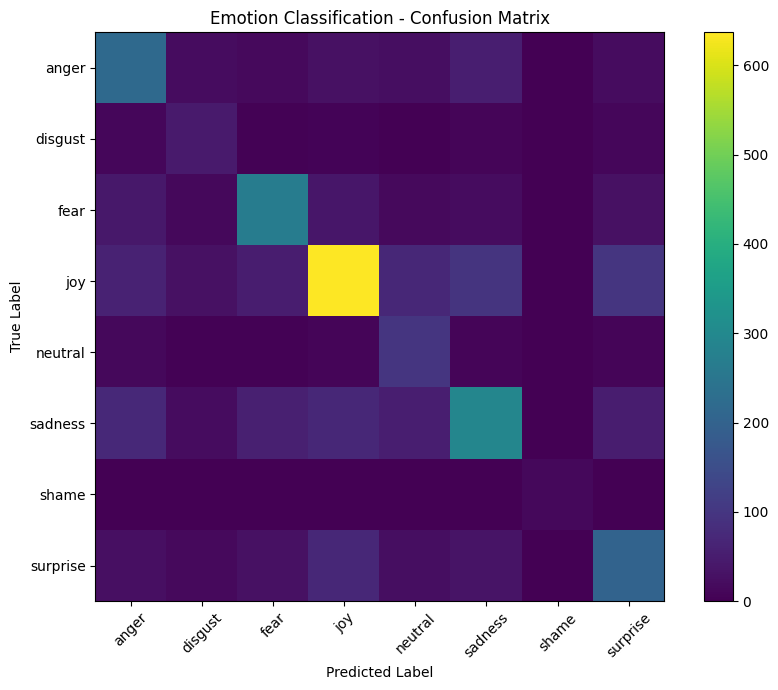

In [ ]:
cm_emotion = confusion_matrix(
    y_emotion_test,
    emotion_test_pred,
    labels=emotion_model.classes_
)

plt.figure(figsize=(9, 7))

plt.imshow(cm_emotion)

plt.title("Emotion Classification - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(
    range(len(emotion_model.classes_)),
    emotion_model.classes_,
    rotation=45
)

plt.yticks(
    range(len(emotion_model.classes_)),
    emotion_model.classes_
)

plt.colorbar()

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# MENTAL HEALTH MODEL — TF-IDF
# ============================================

mental_vectorizer = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_mental_train_tfidf = mental_vectorizer.fit_transform(
    X_mental_train
)

X_mental_val_tfidf = mental_vectorizer.transform(
    X_mental_val
)

X_mental_test_tfidf = mental_vectorizer.transform(
    X_mental_test
)

print("Mental-health TF-IDF shape:")
print("Training:", X_mental_train_tfidf.shape)
print("Validation:", X_mental_val_tfidf.shape)
print("Testing:", X_mental_test_tfidf.shape)

Mental-health TF-IDF shape:
Training: (40844, 30000)
Validation: (5105, 30000)
Testing: (5106, 30000)


In [ ]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
mental_lr = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

# Train the model
mental_lr.fit(
    X_mental_train_tfidf,
    y_mental_train
)

print("Mental Health Logistic Regression trained successfully!")

Mental Health Logistic Regression trained successfully!


In [ ]:
mental_lr_pred = mental_lr.predict(
    X_mental_test_tfidf
)

print("Predictions generated successfully!")
print("Number of predictions:", len(mental_lr_pred))

Predictions generated successfully!
Number of predictions: 5106


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("=" * 70)
print("MENTAL HEALTH MODEL — LOGISTIC REGRESSION — TEST")
print("=" * 70)

print("Accuracy:",
      accuracy_score(y_mental_test, mental_lr_pred))

print("Macro Precision:",
      precision_score(
          y_mental_test,
          mental_lr_pred,
          average='macro',
          zero_division=0
      ))

print("Macro Recall:",
      recall_score(
          y_mental_test,
          mental_lr_pred,
          average='macro',
          zero_division=0
      ))

print("Macro F1:",
      f1_score(
          y_mental_test,
          mental_lr_pred,
          average='macro',
          zero_division=0
      ))

print("\nClassification Report")
print("-" * 70)

print(
    classification_report(
        y_mental_test,
        mental_lr_pred,
        zero_division=0
    )
)

MENTAL HEALTH MODEL — LOGISTIC REGRESSION — TEST
Accuracy: 0.7710536623580102
Macro Precision: 0.6960665593504853
Macro Recall: 0.744688254796405
Macro F1: 0.7146814464024948

Classification Report
----------------------------------------------------------------------
                      precision    recall  f1-score   support

             Anxiety       0.77      0.84      0.80       362
             Bipolar       0.71      0.73      0.72       250
          Depression       0.80      0.63      0.70      1508
              Normal       0.90      0.92      0.91      1604
Personality disorder       0.52      0.62      0.57        89
              Stress       0.49      0.72      0.58       229
            Suicidal       0.68      0.75      0.71      1064

            accuracy                           0.77      5106
           macro avg       0.70      0.74      0.71      5106
        weighted avg       0.78      0.77      0.77      5106



In [ ]:
import time
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []


def evaluate_model(
    model,
    model_name,
    X_train,
    y_train,
    X_test,
    y_test,
    dataset_name
):

    start_time = time.time()

    # Train
    model.fit(X_train, y_train)

    training_time = time.time() - start_time

    # Predict
    predictions = model.predict(X_test)

    # Metrics
    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test,
        predictions,
        average='macro',
        zero_division=0
    )
    recall = recall_score(
        y_test,
        predictions,
        average='macro',
        zero_division=0
    )
    f1 = f1_score(
        y_test,
        predictions,
        average='macro',
        zero_division=0
    )

    results.append({
        'Dataset': dataset_name,
        'Model': model_name,
        'Accuracy': accuracy,
        'Macro Precision': precision,
        'Macro Recall': recall,
        'Macro F1': f1,
        'Training Time (sec)': training_time
    })

    print(f"\n{dataset_name} - {model_name}")
    print("-" * 50)
    print(f"Accuracy:     {accuracy:.4f}")
    print(f"Macro F1:     {f1:.4f}")
    print(f"Training time:{training_time:.2f}s")

    return model, predictions

In [ ]:
from sklearn.linear_model import LogisticRegression

# ============================================
# EMOTION - LOGISTIC REGRESSION
# ============================================

emotion_lr = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

emotion_lr, emotion_lr_pred = evaluate_model(
    emotion_lr,
    "Logistic Regression",
    X_emotion_train_tfidf,
    y_emotion_train,
    X_emotion_test_tfidf,
    y_emotion_test,
    "Emotion"
)


Emotion - Logistic Regression
--------------------------------------------------
Accuracy:     0.5710
Macro F1:     0.5782
Training time:12.25s


In [ ]:
# ============================================
# MENTAL HEALTH - LOGISTIC REGRESSION
# ============================================

mental_lr = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

mental_lr, mental_lr_pred = evaluate_model(
    mental_lr,
    "Logistic Regression",
    X_mental_train_tfidf,
    y_mental_train,
    X_mental_test_tfidf,
    y_mental_test,
    "Mental Health"
)


Mental Health - Logistic Regression
--------------------------------------------------
Accuracy:     0.7711
Macro F1:     0.7147
Training time:25.00s


In [ ]:
from sklearn.naive_bayes import MultinomialNB

In [ ]:
emotion_nb = MultinomialNB()

emotion_nb, emotion_nb_pred = evaluate_model(
    emotion_nb,
    "Naive Bayes",
    X_emotion_train_tfidf,
    y_emotion_train,
    X_emotion_test_tfidf,
    y_emotion_test,
    "Emotion"
)


Emotion - Naive Bayes
--------------------------------------------------
Accuracy:     0.4696
Macro F1:     0.2452
Training time:0.13s


In [ ]:
mental_nb = MultinomialNB()

mental_nb, mental_nb_pred = evaluate_model(
    mental_nb,
    "Naive Bayes",
    X_mental_train_tfidf,
    y_mental_train,
    X_mental_test_tfidf,
    y_mental_test,
    "Mental Health"
)


Mental Health - Naive Bayes
--------------------------------------------------
Accuracy:     0.6767
Macro F1:     0.4561
Training time:0.31s


In [ ]:
from sklearn.svm import LinearSVC

In [ ]:
emotion_svm = LinearSVC(
    class_weight='balanced',
    random_state=42
)

emotion_svm, emotion_svm_pred = evaluate_model(
    emotion_svm,
    "SVM",
    X_emotion_train_tfidf,
    y_emotion_train,
    X_emotion_test_tfidf,
    y_emotion_test,
    "Emotion"
)


Emotion - SVM
--------------------------------------------------
Accuracy:     0.6039
Macro F1:     0.5973
Training time:2.28s


In [ ]:
mental_svm = LinearSVC(
    class_weight='balanced',
    random_state=42
)

mental_svm, mental_svm_pred = evaluate_model(
    mental_svm,
    "SVM",
    X_mental_train_tfidf,
    y_mental_train,
    X_mental_test_tfidf,
    y_mental_test,
    "Mental Health"
)


Mental Health - SVM
--------------------------------------------------
Accuracy:     0.7691
Macro F1:     0.7046
Training time:31.81s


In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

def plot_confusion_matrix(
    y_true,
    predictions,
    model,
    dataset_name,
    model_name
):

    cm = confusion_matrix(
        y_true,
        predictions,
        labels=model.classes_
    )

    plt.figure(figsize=(9, 7))
    plt.imshow(cm)

    plt.title(f"{dataset_name} - {model_name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")

    plt.xticks(
        range(len(model.classes_)),
        model.classes_,
        rotation=45
    )

    plt.yticks(
        range(len(model.classes_)),
        model.classes_
    )

    plt.colorbar()

    plt.tight_layout()
    plt.show()

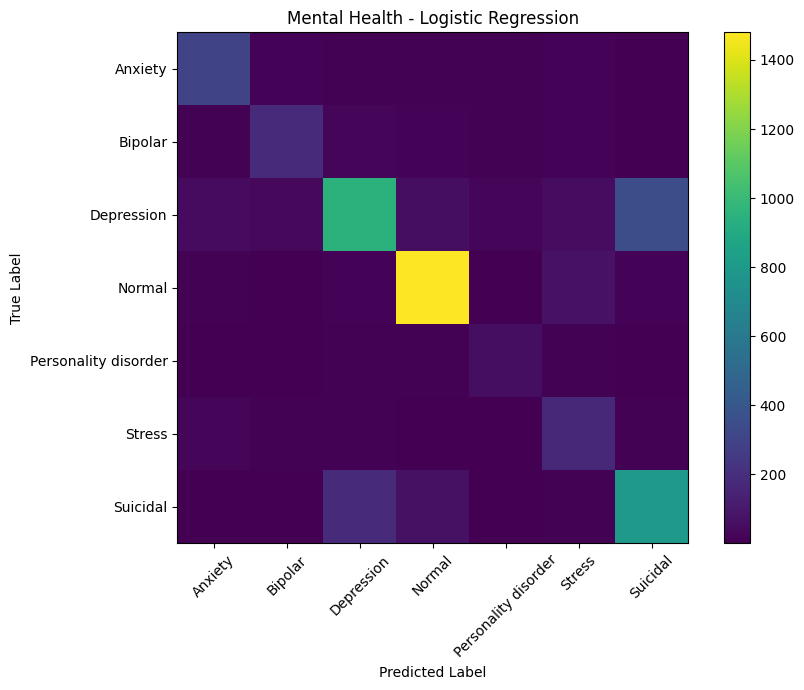

In [ ]:
plot_confusion_matrix(
    y_mental_test,
    mental_lr_pred,
    mental_lr,
    "Mental Health",
    "Logistic Regression"
)

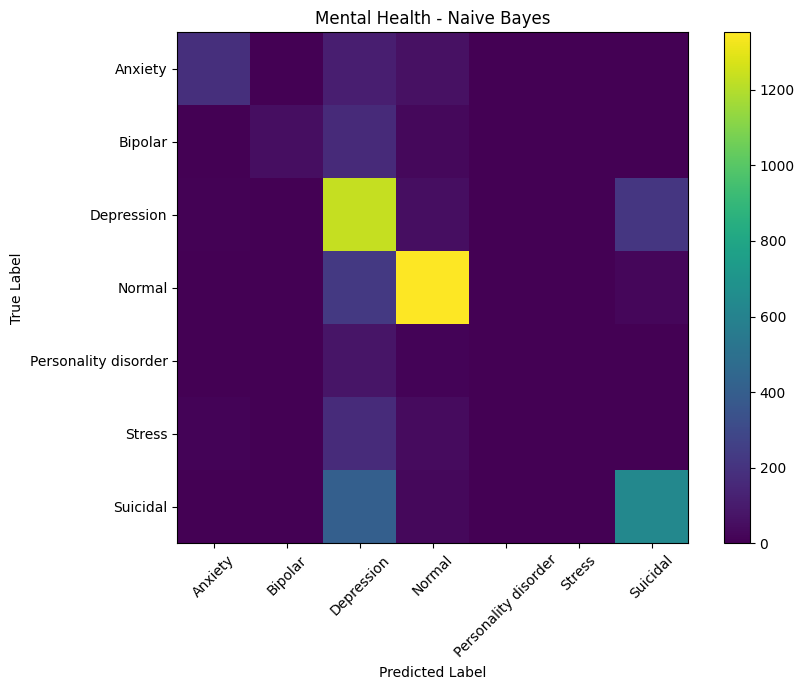

In [ ]:
plot_confusion_matrix(
    y_mental_test,
    mental_nb_pred,
    mental_nb,
    "Mental Health",
    "Naive Bayes"
)

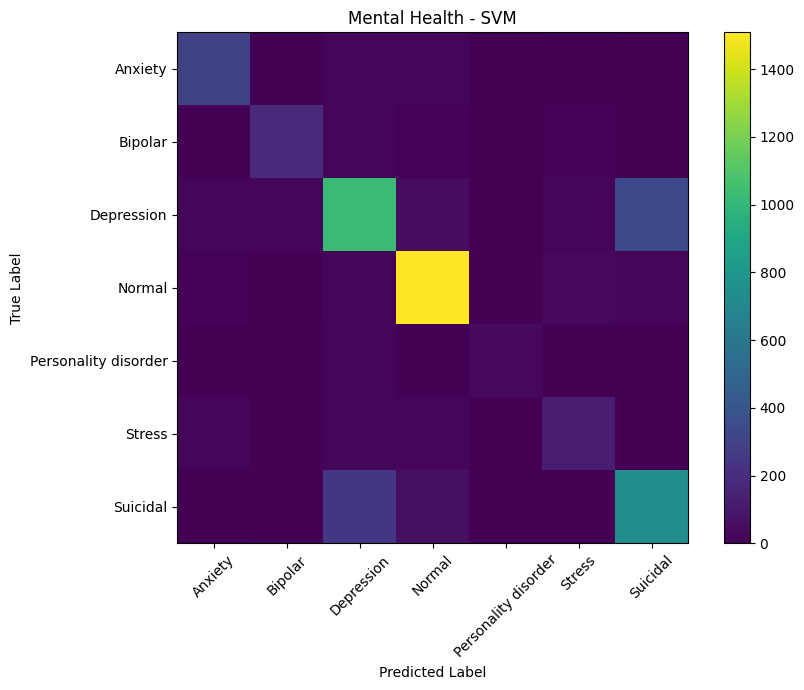

In [ ]:
plot_confusion_matrix(
    y_mental_test,
    mental_svm_pred,
    mental_svm,
    "Mental Health",
    "SVM"
)

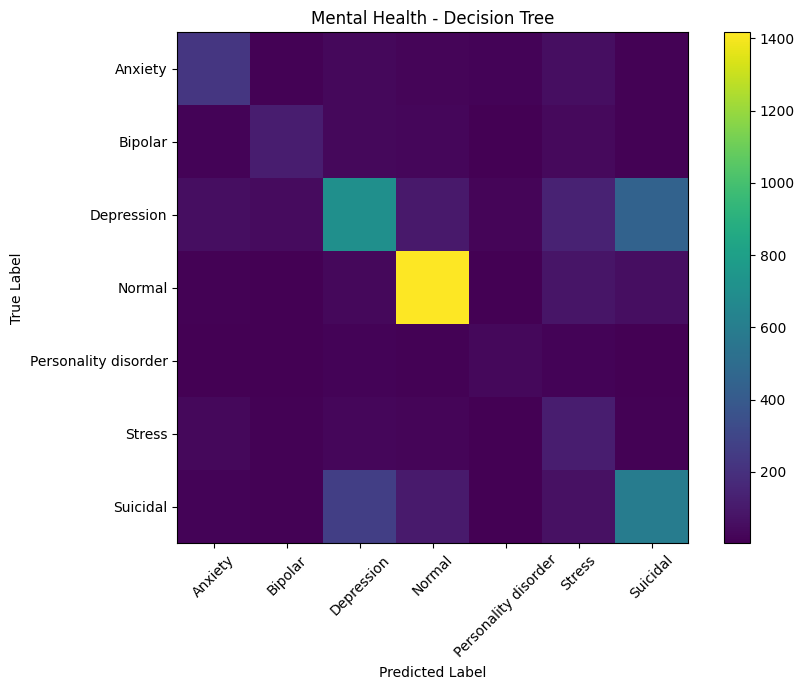

In [ ]:
plot_confusion_matrix(
    y_mental_test,
    mental_dt_pred,
    mental_dt,
    "Mental Health",
    "Decision Tree"
)

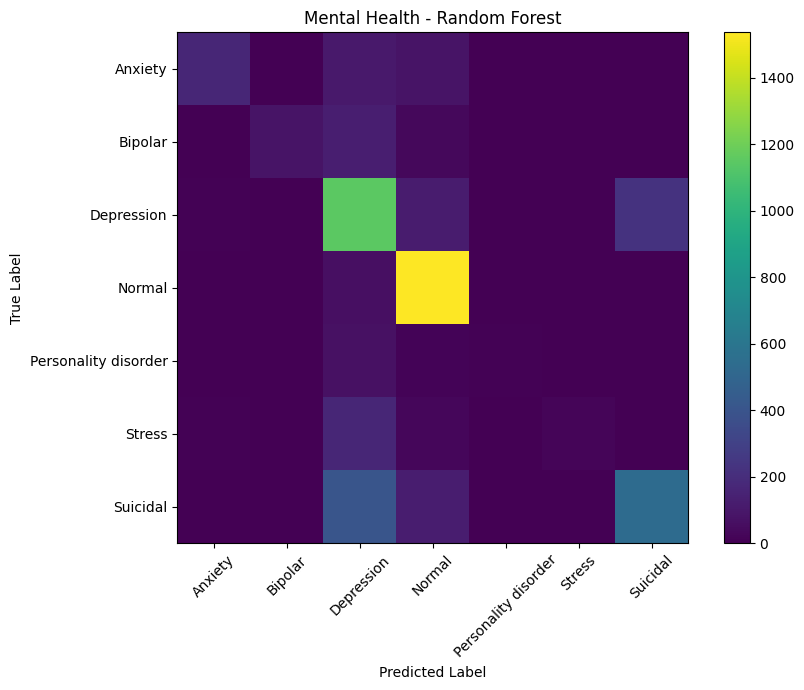

In [ ]:
plot_confusion_matrix(
    y_mental_test,
    mental_rf_pred,
    mental_rf,
    "Mental Health",
    "Random Forest"
)

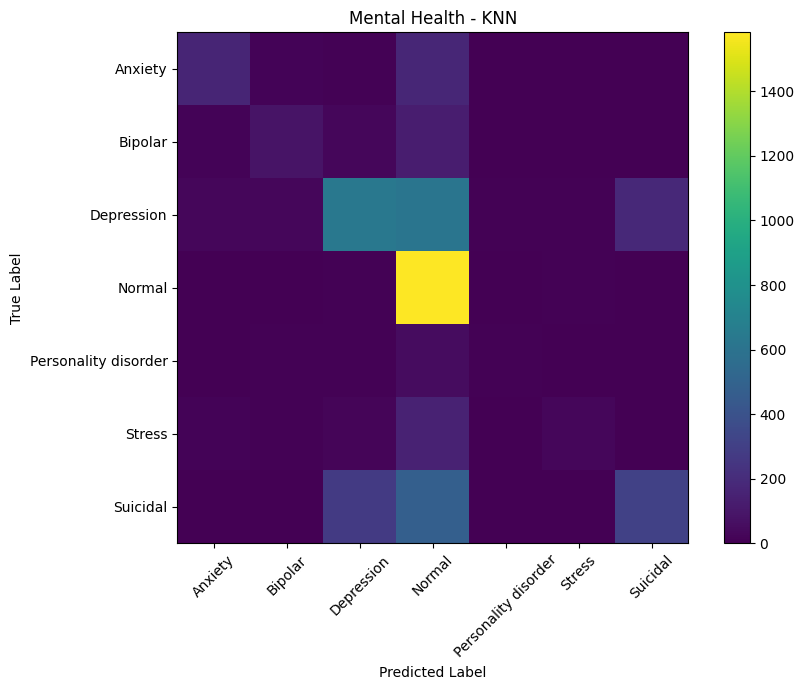

In [ ]:
plot_confusion_matrix(
    y_mental_test,
    mental_knn_pred,
    mental_knn,
    "Mental Health",
    "KNN"
)

In [ ]:
from sklearn.tree import DecisionTreeClassifier

In [ ]:
emotion_dt = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42,
    max_depth=30
)

emotion_dt, emotion_dt_pred = evaluate_model(
    emotion_dt,
    "Decision Tree",
    X_emotion_train_tfidf,
    y_emotion_train,
    X_emotion_test_tfidf,
    y_emotion_test,
    "Emotion"
)


Emotion - Decision Tree
--------------------------------------------------
Accuracy:     0.2738
Macro F1:     0.3421
Training time:5.27s


In [ ]:
mental_dt = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42,
    max_depth=30
)

mental_dt, mental_dt_pred = evaluate_model(
    mental_dt,
    "Decision Tree",
    X_mental_train_tfidf,
    y_mental_train,
    X_mental_test_tfidf,
    y_mental_test,
    "Mental Health"
)


Mental Health - Decision Tree
--------------------------------------------------
Accuracy:     0.6291
Macro F1:     0.5386
Training time:76.43s


In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
emotion_rf = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

emotion_rf, emotion_rf_pred = evaluate_model(
    emotion_rf,
    "Random Forest",
    X_emotion_train_tfidf,
    y_emotion_train,
    X_emotion_test_tfidf,
    y_emotion_test,
    "Emotion"
)


Emotion - Random Forest
--------------------------------------------------
Accuracy:     0.5060
Macro F1:     0.4454
Training time:223.86s


In [ ]:
mental_rf = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

mental_rf, mental_rf_pred = evaluate_model(
    mental_rf,
    "Random Forest",
    X_mental_train_tfidf,
    y_mental_train,
    X_mental_test_tfidf,
    y_mental_test,
    "Mental Health"
)


Mental Health - Random Forest
--------------------------------------------------
Accuracy:     0.6863
Macro F1:     0.5026
Training time:488.12s


In [ ]:
from sklearn.decomposition import TruncatedSVD

In [ ]:
svd = TruncatedSVD(
    n_components=300,
    random_state=42
)

X_emotion_train_svd = svd.fit_transform(
    X_emotion_train_tfidf
)

X_emotion_test_svd = svd.transform(
    X_emotion_test_tfidf
)

print(X_emotion_train_svd.shape)
print(X_emotion_test_svd.shape)

(24834, 300)
(3105, 300)


In [ ]:
mental_svd = TruncatedSVD(
    n_components=300,
    random_state=42
)

X_mental_train_svd = mental_svd.fit_transform(
    X_mental_train_tfidf
)

X_mental_test_svd = mental_svd.transform(
    X_mental_test_tfidf
)

print(X_mental_train_svd.shape)
print(X_mental_test_svd.shape)

(40844, 300)
(5106, 300)


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
emotion_knn = KNeighborsClassifier(
    n_neighbors=5,
    n_jobs=-1
)

emotion_knn, emotion_knn_pred = evaluate_model(
    emotion_knn,
    "KNN",
    X_emotion_train_svd,
    y_emotion_train,
    X_emotion_test_svd,
    y_emotion_test,
    "Emotion"
)


Emotion - KNN
--------------------------------------------------
Accuracy:     0.3865
Macro F1:     0.2702
Training time:0.06s


In [ ]:
mental_knn = KNeighborsClassifier(
    n_neighbors=5,
    n_jobs=-1
)

mental_knn, mental_knn_pred = evaluate_model(
    mental_knn,
    "KNN",
    X_mental_train_svd,
    y_mental_train,
    X_mental_test_svd,
    y_mental_test,
    "Mental Health"
)


Mental Health - KNN
--------------------------------------------------
Accuracy:     0.5476
Macro F1:     0.4081
Training time:0.05s


In [ ]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    ["Dataset", "Macro F1"],
    ascending=[True, False]
)

display(results_df)

,Dataset,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Training Time (sec)
4,Emotion,SVM,0.603865,0.585492,0.613569,0.597327,2.282674
0,Emotion,Logistic Regression,0.571014,0.555655,0.627727,0.578228,12.245198
8,Emotion,Random Forest,0.505958,0.703565,0.399252,0.445397,223.862725
6,Emotion,Decision Tree,0.273752,0.384486,0.406287,0.342101,5.271862
10,Emotion,KNN,0.386473,0.282477,0.273005,0.270203,0.061019
2,Emotion,Naive Bayes,0.469565,0.528216,0.239530,0.245176,0.133488
1,Mental Health,Logistic Regression,0.771054,0.696067,0.744688,0.714681,24.996042
5,Mental Health,SVM,0.769095,0.721772,0.694478,0.704560,31.807744
7,Mental Health,Decision Tree,0.629064,0.543386,0.555239,0.538550,76.427963
9,Mental Health,Random Forest,0.686251,0.811883,0.457262,0.502570,488.123449


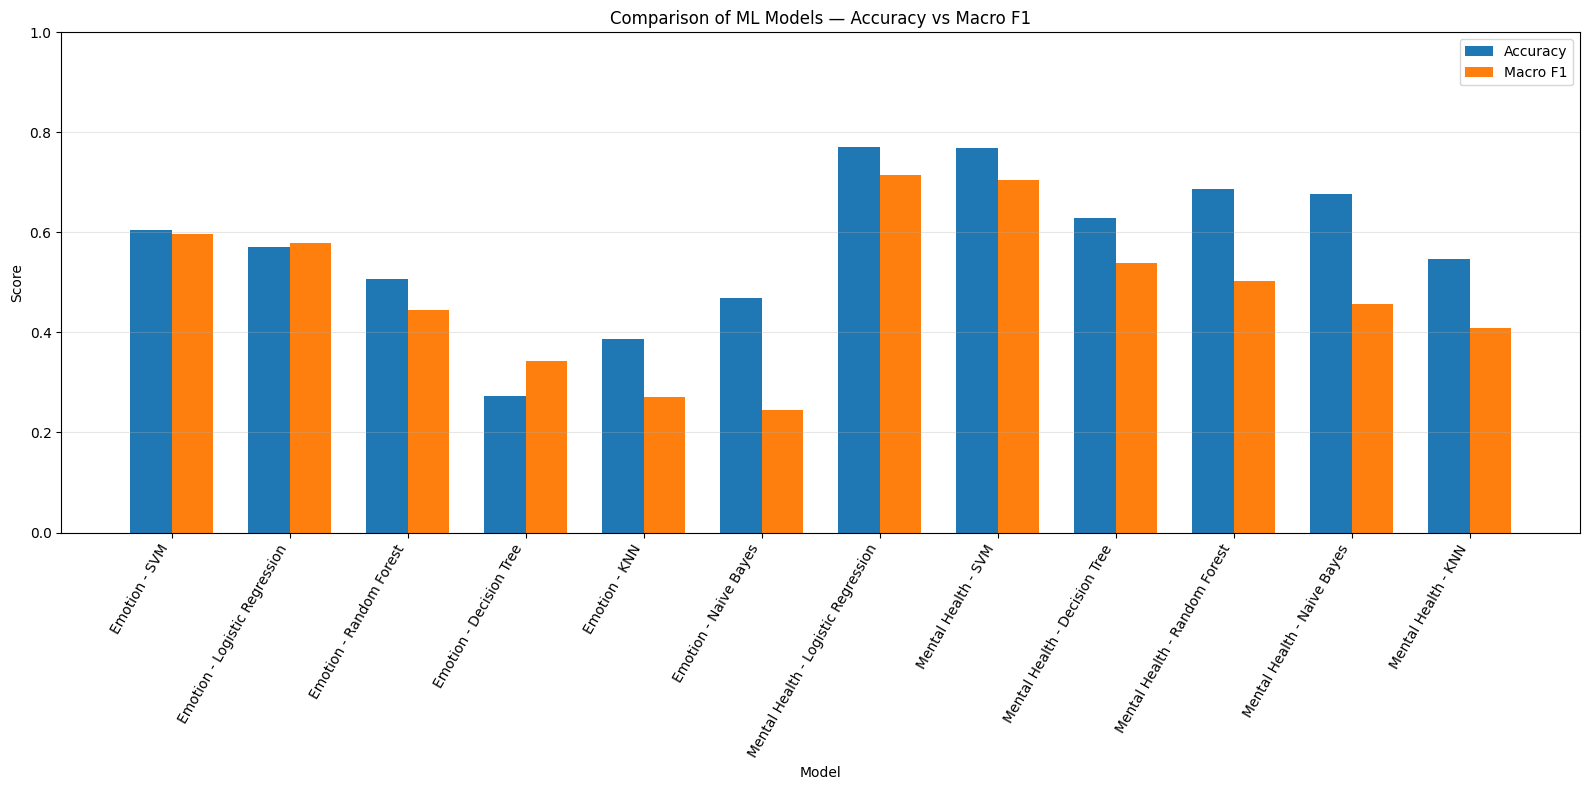

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Make a copy
plot_df = results_df.copy()

# Create a combined label
plot_df["Model_Dataset"] = (
    plot_df["Dataset"] + " - " + plot_df["Model"]
)

# Positions
x = np.arange(len(plot_df))
width = 0.35

plt.figure(figsize=(16, 8))

# Accuracy
plt.bar(
    x - width/2,
    plot_df["Accuracy"],
    width,
    label="Accuracy"
)

# Macro F1
plt.bar(
    x + width/2,
    plot_df["Macro F1"],
    width,
    label="Macro F1"
)

# Labels
plt.xticks(
    x,
    plot_df["Model_Dataset"],
    rotation=60,
    ha="right"
)

plt.ylabel("Score")
plt.xlabel("Model")
plt.title("Comparison of ML Models — Accuracy vs Macro F1")

plt.ylim(0, 1)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

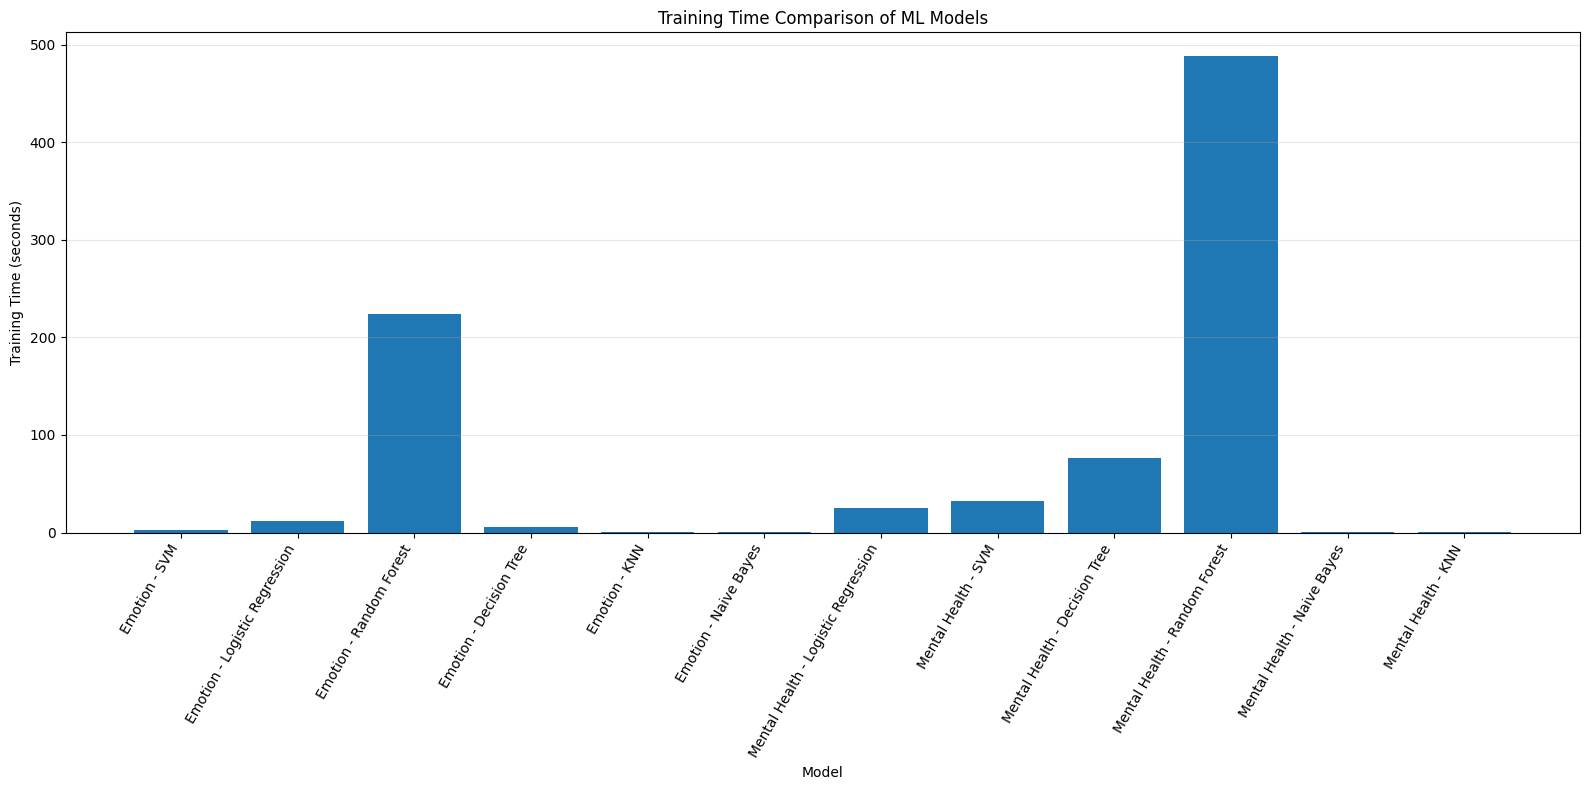

In [ ]:
plt.figure(figsize=(16, 8))

plt.bar(
    x,
    plot_df["Training Time (sec)"]
)

plt.xticks(
    x,
    plot_df["Model_Dataset"],
    rotation=60,
    ha="right"
)

plt.ylabel("Training Time (seconds)")
plt.xlabel("Model")
plt.title("Training Time Comparison of ML Models")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

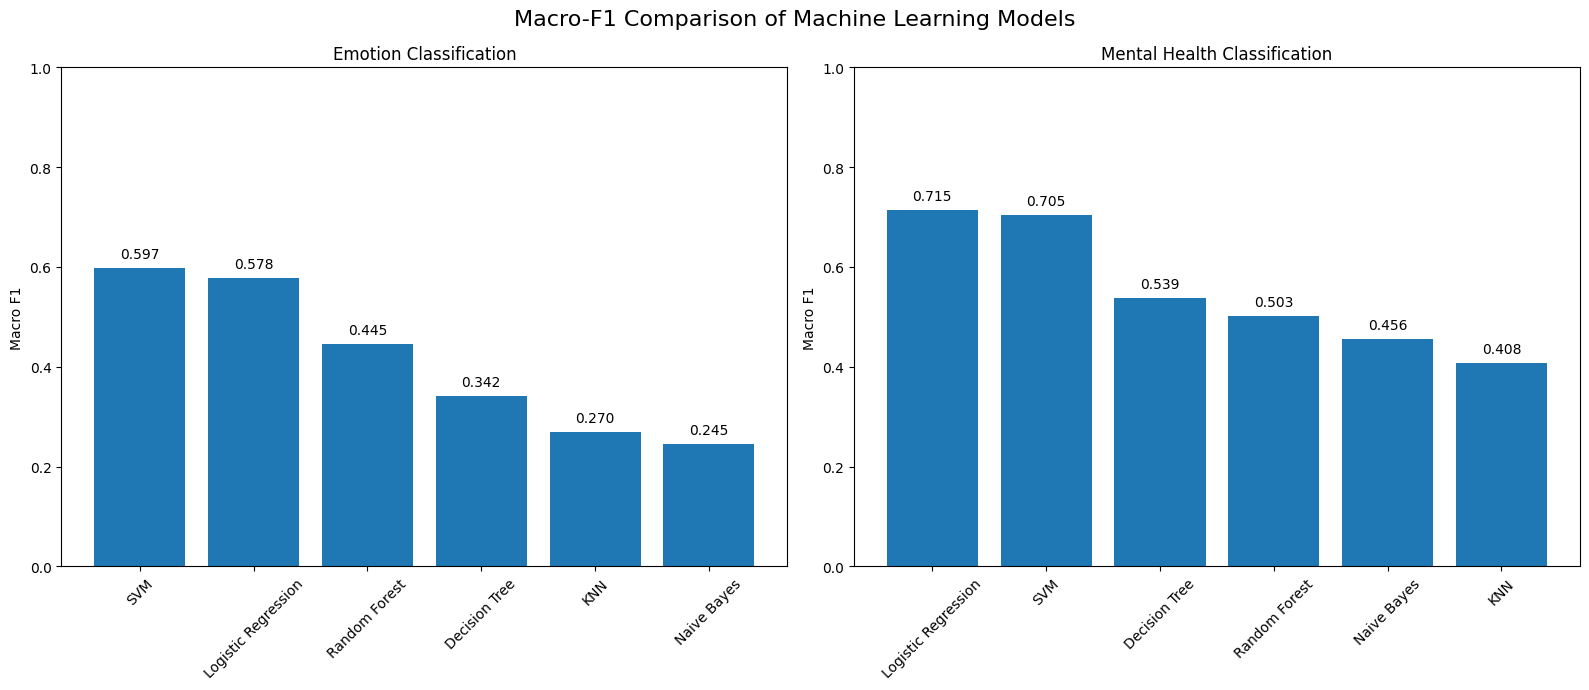

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Copy results
plot_df = results_df.copy()

# Keep only the Macro-F1 values
emotion_df = plot_df[
    plot_df["Dataset"] == "Emotion"
].sort_values("Macro F1", ascending=False)

mental_df = plot_df[
    plot_df["Dataset"] == "Mental Health"
].sort_values("Macro F1", ascending=False)

# Create figure
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# -----------------------------------------
# EMOTION
# -----------------------------------------

axes[0].bar(
    emotion_df["Model"],
    emotion_df["Macro F1"]
)

axes[0].set_title("Emotion Classification")
axes[0].set_ylabel("Macro F1")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=45)

# Add values
for i, value in enumerate(emotion_df["Macro F1"]):
    axes[0].text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

# -----------------------------------------
# MENTAL HEALTH
# -----------------------------------------

axes[1].bar(
    mental_df["Model"],
    mental_df["Macro F1"]
)

axes[1].set_title("Mental Health Classification")
axes[1].set_ylabel("Macro F1")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=45)

# Add values
for i, value in enumerate(mental_df["Macro F1"]):
    axes[1].text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.suptitle(
    "Macro-F1 Comparison of Machine Learning Models",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# TEST DIFFERENT SVM KERNELS — EMOTION DATASET
# ============================================

import time
import pandas as pd

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

svm_results = []

kernels = ["linear", "rbf", "poly", "sigmoid"]

for kernel in kernels:

    print("\n" + "=" * 70)
    print(f"SVM KERNEL: {kernel.upper()}")
    print("=" * 70)

    model = SVC(
        kernel=kernel,
        class_weight="balanced",
        random_state=42
    )

    start_time = time.perf_counter()

    model.fit(
        X_emotion_train_tfidf,
        y_emotion_train
    )

    training_time = time.perf_counter() - start_time

    predictions = model.predict(
        X_emotion_test_tfidf
    )

    accuracy = accuracy_score(
        y_emotion_test,
        predictions
    )

    macro_precision = precision_score(
        y_emotion_test,
        predictions,
        average="macro",
        zero_division=0
    )

    macro_recall = recall_score(
        y_emotion_test,
        predictions,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_emotion_test,
        predictions,
        average="macro",
        zero_division=0
    )

    svm_results.append({
        "SVM Kernel": kernel,
        "Accuracy": accuracy,
        "Macro Precision": macro_precision,
        "Macro Recall": macro_recall,
        "Macro F1": macro_f1,
        "Training Time (sec)": training_time
    })

    print(f"Accuracy:        {accuracy:.4f}")
    print(f"Macro Precision: {macro_precision:.4f}")
    print(f"Macro Recall:    {macro_recall:.4f}")
    print(f"Macro F1:        {macro_f1:.4f}")
    print(f"Training Time:   {training_time:.2f} sec")


# ============================================
# FINAL COMPARISON TABLE
# ============================================

svm_results_df = pd.DataFrame(svm_results)

svm_results_df = svm_results_df.sort_values(
    "Macro F1",
    ascending=False
).reset_index(drop=True)

display(svm_results_df)


SVM KERNEL: LINEAR
Accuracy:        0.5852
Macro Precision: 0.5755
Macro Recall:    0.5939
Macro F1:        0.5808
Training Time:   260.88 sec

SVM KERNEL: RBF
Accuracy:        0.5881
Macro Precision: 0.6166
Macro Recall:    0.4813
Macro F1:        0.5123
Training Time:   440.95 sec

SVM KERNEL: POLY
Accuracy:        0.4090
Macro Precision: 0.5570
Macro Recall:    0.2047
Macro F1:        0.2064
Training Time:   535.31 sec

SVM KERNEL: SIGMOID
Accuracy:        0.5617
Macro Precision: 0.5448
Macro Recall:    0.6051
Macro F1:        0.5654
Training Time:   253.99 sec


,SVM Kernel,Accuracy,Macro Precision,Macro Recall,Macro F1,Training Time (sec)
0,linear,0.585185,0.575452,0.593933,0.580843,260.882230
1,sigmoid,0.561675,0.544792,0.605082,0.565357,253.991042
2,rbf,0.588084,0.616551,0.481345,0.512315,440.953712
3,poly,0.409018,0.556994,0.204740,0.206445,535.306768


In [ ]:
# ============================================
# LOGISTIC REGRESSION TYPES — EMOTION DATASET
# ============================================

import time
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

lr_results = []

models = {
    "One-vs-Rest": LogisticRegression(
        multi_class="ovr",
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Multinomial": LogisticRegression(
        multi_class="multinomial",
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
}


for model_name, model in models.items():

    print("\n" + "=" * 70)
    print(f"LOGISTIC REGRESSION: {model_name.upper()}")
    print("=" * 70)

    # Training time
    start_time = time.perf_counter()

    model.fit(
        X_emotion_train_tfidf,
        y_emotion_train
    )

    training_time = time.perf_counter() - start_time

    # Prediction
    predictions = model.predict(
        X_emotion_test_tfidf
    )

    # Metrics
    accuracy = accuracy_score(
        y_emotion_test,
        predictions
    )

    macro_precision = precision_score(
        y_emotion_test,
        predictions,
        average="macro",
        zero_division=0
    )

    macro_recall = recall_score(
        y_emotion_test,
        predictions,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_emotion_test,
        predictions,
        average="macro",
        zero_division=0
    )

    lr_results.append({
        "Logistic Regression Type": model_name,
        "Accuracy": accuracy,
        "Macro Precision": macro_precision,
        "Macro Recall": macro_recall,
        "Macro F1": macro_f1,
        "Training Time (sec)": training_time
    })

    print(f"Accuracy:        {accuracy:.4f}")
    print(f"Macro Precision: {macro_precision:.4f}")
    print(f"Macro Recall:    {macro_recall:.4f}")
    print(f"Macro F1:        {macro_f1:.4f}")
    print(f"Training Time:   {training_time:.2f} sec")


# ============================================
# COMPARISON TABLE
# ============================================

lr_results_df = pd.DataFrame(lr_results)

lr_results_df = lr_results_df.sort_values(
    "Macro F1",
    ascending=False
).reset_index(drop=True)

display(lr_results_df)


LOGISTIC REGRESSION: ONE-VS-REST


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


Accuracy:        0.6048
Macro Precision: 0.5882
Macro Recall:    0.6055
Macro F1:        0.5943
Training Time:   6.60 sec

LOGISTIC REGRESSION: MULTINOMIAL


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Accuracy:        0.5710
Macro Precision: 0.5557
Macro Recall:    0.6277
Macro F1:        0.5782
Training Time:   12.59 sec


,Logistic Regression Type,Accuracy,Macro Precision,Macro Recall,Macro F1,Training Time (sec)
0,One-vs-Rest,0.604831,0.588245,0.605538,0.594313,6.603463
1,Multinomial,0.571014,0.555655,0.627727,0.578228,12.590150


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import time
import pandas as pd

rf_results = []

models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Balanced Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Random Forest (200 Trees)": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Random Forest (Max Depth 20)": RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        random_state=42,
        n_jobs=-1
    )
}

for model_name, model in models.items():

    print(f"\nTraining: {model_name}")

    start_time = time.time()

    model.fit(
        X_emotion_train_tfidf,
        y_emotion_train
    )

    y_pred = model.predict(
        X_emotion_test_tfidf
    )

    training_time = time.time() - start_time

    accuracy = accuracy_score(
        y_emotion_test,
        y_pred
    )

    precision = precision_score(
        y_emotion_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_emotion_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_emotion_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    rf_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1,
        "Training Time (s)": training_time
    })

    print(f"Accuracy:       {accuracy:.4f}")
    print(f"Macro Precision:{precision:.4f}")
    print(f"Macro Recall:   {recall:.4f}")
    print(f"Macro F1:       {f1:.4f}")
    print(f"Training Time:  {training_time:.2f}s")


# Create comparison table
rf_results_df = pd.DataFrame(rf_results)

# Sort according to Macro F1
rf_results_df = rf_results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("\n===== RANDOM FOREST COMPARISON =====")
display(rf_results_df)


Training: Random Forest
Accuracy:       0.5337
Macro Precision:0.7225
Macro Recall:   0.4394
Macro F1:       0.4784
Training Time:  88.95s

Training: Balanced Random Forest
Accuracy:       0.5066
Macro Precision:0.6965
Macro Recall:   0.4231
Macro F1:       0.4629
Training Time:  107.24s

Training: Random Forest (200 Trees)
Accuracy:       0.5359
Macro Precision:0.7264
Macro Recall:   0.4437
Macro F1:       0.4849
Training Time:  181.53s

Training: Random Forest (Max Depth 20)
Accuracy:       0.3765
Macro Precision:0.5091
Macro Recall:   0.1588
Macro F1:       0.1284
Training Time:  4.46s

===== RANDOM FOREST COMPARISON =====


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Training Time (s)
0,Random Forest (200 Trees),0.535910,0.726446,0.443674,0.484918,181.527384
1,Random Forest,0.533655,0.722548,0.439412,0.478362,88.950620
2,Balanced Random Forest,0.506602,0.696496,0.423113,0.462899,107.243163
3,Random Forest (Max Depth 20),0.376490,0.509061,0.158836,0.128385,4.461651


In [ ]:
from sklearn.naive_bayes import MultinomialNB, BernoulliNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import time
import pandas as pd

nb_results = []

models = {
    "Multinomial Naive Bayes": MultinomialNB(),

    "Bernoulli Naive Bayes": BernoulliNB()
}

for model_name, model in models.items():

    print(f"\nTraining: {model_name}")

    start_time = time.time()

    # Train
    model.fit(
        X_emotion_train_tfidf,
        y_emotion_train
    )

    # Predict
    y_pred = model.predict(
        X_emotion_test_tfidf
    )

    training_time = time.time() - start_time

    # Metrics
    accuracy = accuracy_score(
        y_emotion_test,
        y_pred
    )

    precision = precision_score(
        y_emotion_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_emotion_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_emotion_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    nb_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1,
        "Training Time (s)": training_time
    })

    print(f"Accuracy:        {accuracy:.4f}")
    print(f"Macro Precision: {precision:.4f}")
    print(f"Macro Recall:    {recall:.4f}")
    print(f"Macro F1:        {f1:.4f}")
    print(f"Training Time:   {training_time:.2f}s")


# Create comparison table
nb_results_df = pd.DataFrame(nb_results)

# Rank by Macro F1
nb_results_df = nb_results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("\n===== NAIVE BAYES COMPARISON =====")
display(nb_results_df)


Training: Multinomial Naive Bayes
Accuracy:        0.4696
Macro Precision: 0.5282
Macro Recall:    0.2395
Macro F1:        0.2452
Training Time:   0.08s

Training: Bernoulli Naive Bayes
Accuracy:        0.5246
Macro Precision: 0.4878
Macro Recall:    0.3004
Macro F1:        0.3096
Training Time:   0.08s

===== NAIVE BAYES COMPARISON =====


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Training Time (s)
0,Bernoulli Naive Bayes,0.524638,0.487819,0.300425,0.309618,0.082633
1,Multinomial Naive Bayes,0.469565,0.528216,0.239530,0.245176,0.076646


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import time
import pandas as pd

dt_results = []

models = {
    "Decision Tree - Gini": DecisionTreeClassifier(
        criterion="gini",
        random_state=42
    ),

    "Decision Tree - Entropy": DecisionTreeClassifier(
        criterion="entropy",
        random_state=42
    ),

    "Decision Tree - Log Loss": DecisionTreeClassifier(
        criterion="log_loss",
        random_state=42
    ),

    "Decision Tree - Balanced": DecisionTreeClassifier(
        criterion="gini",
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree - Max Depth 20": DecisionTreeClassifier(
        criterion="gini",
        max_depth=20,
        random_state=42
    )
}

for model_name, model in models.items():

    print(f"\nTraining: {model_name}")

    start_time = time.time()

    # Train
    model.fit(
        X_emotion_train_tfidf,
        y_emotion_train
    )

    # Predict
    y_pred = model.predict(
        X_emotion_test_tfidf
    )

    training_time = time.time() - start_time

    # Metrics
    accuracy = accuracy_score(
        y_emotion_test,
        y_pred
    )

    precision = precision_score(
        y_emotion_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_emotion_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_emotion_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    dt_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1,
        "Training Time (s)": training_time
    })

    print(f"Accuracy:        {accuracy:.4f}")
    print(f"Macro Precision: {precision:.4f}")
    print(f"Macro Recall:    {recall:.4f}")
    print(f"Macro F1:        {f1:.4f}")
    print(f"Training Time:   {training_time:.2f}s")


# Create results table
dt_results_df = pd.DataFrame(dt_results)

# Rank models by Macro F1
dt_results_df = dt_results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("\n===== DECISION TREE COMPARISON =====")
display(dt_results_df)


Training: Decision Tree - Gini
Accuracy:        0.4544
Macro Precision: 0.4504
Macro Recall:    0.4380
Macro F1:        0.4418
Training Time:   22.20s

Training: Decision Tree - Entropy
Accuracy:        0.4010
Macro Precision: 0.3997
Macro Recall:    0.3950
Macro F1:        0.3959
Training Time:   22.58s

Training: Decision Tree - Log Loss
Accuracy:        0.4010
Macro Precision: 0.3997
Macro Recall:    0.3950
Macro F1:        0.3959
Training Time:   21.41s

Training: Decision Tree - Balanced
Accuracy:        0.3974
Macro Precision: 0.4153
Macro Recall:    0.4473
Macro F1:        0.4284
Training Time:   24.91s

Training: Decision Tree - Max Depth 20
Accuracy:        0.4184
Macro Precision: 0.5840
Macro Recall:    0.2269
Macro F1:        0.2419
Training Time:   2.63s

===== DECISION TREE COMPARISON =====


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Training Time (s)
0,Decision Tree - Gini,0.454428,0.450408,0.438040,0.441758,22.204949
1,Decision Tree - Balanced,0.397424,0.415318,0.447312,0.428355,24.907202
2,Decision Tree - Entropy,0.400966,0.399738,0.395038,0.395920,22.581426
3,Decision Tree - Log Loss,0.400966,0.399738,0.395038,0.395920,21.409317
4,Decision Tree - Max Depth 20,0.418357,0.584006,0.226859,0.241889,2.625317


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import time
import pandas as pd

# Encode emotion labels
# --------------------------------------------------

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_emotion_train)
y_test_encoded = label_encoder.transform(y_emotion_test)

print("Emotion classes:")
print(label_encoder.classes_)


knn_results = []

models = {
    "KNN - K=3": KNeighborsClassifier(
        n_neighbors=3,
        weights="uniform",
        metric="minkowski",
        p=2,
        n_jobs=-1
    ),

    "KNN - K=5": KNeighborsClassifier(
        n_neighbors=5,
        weights="uniform",
        metric="minkowski",
        p=2,
        n_jobs=-1
    ),

    "KNN - K=7": KNeighborsClassifier(
        n_neighbors=7,
        weights="uniform",
        metric="minkowski",
        p=2,
        n_jobs=-1
    ),

    "KNN - Manhattan": KNeighborsClassifier(
        n_neighbors=5,
        weights="uniform",
        metric="manhattan",
        n_jobs=-1
    ),

    "KNN - Distance Weighted": KNeighborsClassifier(
        n_neighbors=5,
        weights="distance",
        metric="minkowski",
        p=2,
        n_jobs=-1
    )
}

for model_name, model in models.items():

    print(f"\nTraining: {model_name}")

    start_time = time.time()

    # Train
    model.fit(
        X_emotion_train_tfidf,
       y_train_encoded
    )

    # Predict
    y_pred_encoded = model.predict(
        X_emotion_test_tfidf
    )
      # Convert back to original labels
    y_pred = label_encoder.inverse_transform(
        y_pred_encoded
    )

    total_time = time.time() - start_time

    # Metrics
    accuracy = accuracy_score(
        y_emotion_test,
        y_pred
    )

    precision = precision_score(
        y_emotion_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_emotion_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_emotion_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    knn_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1,
        "Time (s)": total_time
    })

    print(f"Accuracy:        {accuracy:.4f}")
    print(f"Macro Precision: {precision:.4f}")
    print(f"Macro Recall:    {recall:.4f}")
    print(f"Macro F1:        {f1:.4f}")
    print(f"Time:            {total_time:.2f}s")


# Create comparison table
knn_results_df = pd.DataFrame(knn_results)

# Sort by Macro F1
knn_results_df = knn_results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("\n===== KNN COMPARISON =====")
display(knn_results_df)

Emotion classes:
['anger' 'disgust' 'fear' 'joy' 'neutral' 'sadness' 'shame' 'surprise']

Training: KNN - K=3
Accuracy:        0.0940
Macro Precision: 0.6104
Macro Recall:    0.1462
Macro F1:        0.0695
Time:            4.37s

Training: KNN - K=5
Accuracy:        0.0731
Macro Precision: 0.4654
Macro Recall:    0.1357
Macro F1:        0.0445
Time:            4.20s

Training: KNN - K=7
Accuracy:        0.0638
Macro Precision: 0.5409
Macro Recall:    0.1346
Macro F1:        0.0313
Time:            6.03s

Training: KNN - Manhattan
Accuracy:        0.0702
Macro Precision: 0.5331
Macro Recall:    0.1398
Macro F1:        0.0396
Time:            20.80s

Training: KNN - Distance Weighted
Accuracy:        0.0870
Macro Precision: 0.5333
Macro Recall:    0.1457
Macro F1:        0.0631
Time:            6.16s

===== KNN COMPARISON =====


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Time (s)
0,KNN - K=3,0.094042,0.610442,0.146180,0.069497,4.370662
1,KNN - Distance Weighted,0.086957,0.533264,0.145748,0.063105,6.158833
2,KNN - K=5,0.073108,0.465408,0.135726,0.044535,4.195684
3,KNN - Manhattan,0.070209,0.533054,0.139765,0.039645,20.798073
4,KNN - K=7,0.063768,0.540884,0.134553,0.031259,6.033540


In [ ]:
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import BernoulliNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import time
import pandas as pd


# --------------------------------------------------
# Define individual models
# --------------------------------------------------

lr_ovr = LogisticRegression(
    solver="liblinear",
    multi_class="ovr",
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

rf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

nb = BernoulliNB()


# --------------------------------------------------
# Hard Voting Ensemble
# --------------------------------------------------

hard_voting = VotingClassifier(
    estimators=[
        ("lr", lr_ovr),
        ("rf", rf),
        ("nb", nb)
    ],
    voting="hard"
)


# --------------------------------------------------
# Train
# --------------------------------------------------

print("Training Hard Voting Ensemble...")

start_time = time.time()

hard_voting.fit(
    X_emotion_train_tfidf,
    y_emotion_train
)

y_pred = hard_voting.predict(
    X_emotion_test_tfidf
)

training_time = time.time() - start_time


# --------------------------------------------------
# Evaluation
# --------------------------------------------------

accuracy = accuracy_score(
    y_emotion_test,
    y_pred
)

precision = precision_score(
    y_emotion_test,
    y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_emotion_test,
    y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_emotion_test,
    y_pred,
    average="macro",
    zero_division=0
)


print("\n===== HARD VOTING ENSEMBLE =====")
print(f"Accuracy:        {accuracy:.4f}")
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall:    {recall:.4f}")
print(f"Macro F1:        {f1:.4f}")
print(f"Training Time:   {training_time:.2f}s")

Training Hard Voting Ensemble...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(



===== HARD VOTING ENSEMBLE =====
Accuracy:        0.5710
Macro Precision: 0.6201
Macro Recall:    0.4750
Macro F1:        0.5209
Training Time:   221.02s


In [ ]:
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import BernoulliNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import time


# --------------------------------------------------
# Define models
# --------------------------------------------------

lr_ovr = LogisticRegression(
    solver="liblinear",
    multi_class="ovr",
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

rf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

nb = BernoulliNB()


# --------------------------------------------------
# Soft Voting
# --------------------------------------------------

soft_voting = VotingClassifier(
    estimators=[
        ("lr", lr_ovr),
        ("rf", rf),
        ("nb", nb)
    ],
    voting="soft"
)


# --------------------------------------------------
# Train
# --------------------------------------------------

print("Training Soft Voting Ensemble...")

start_time = time.time()

soft_voting.fit(
    X_emotion_train_tfidf,
    y_emotion_train
)

y_pred = soft_voting.predict(
    X_emotion_test_tfidf
)

training_time = time.time() - start_time


# --------------------------------------------------
# Evaluation
# --------------------------------------------------

accuracy = accuracy_score(
    y_emotion_test,
    y_pred
)

precision = precision_score(
    y_emotion_test,
    y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_emotion_test,
    y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_emotion_test,
    y_pred,
    average="macro",
    zero_division=0
)


print("\n===== SOFT VOTING ENSEMBLE =====")
print(f"Accuracy:        {accuracy:.4f}")
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall:    {recall:.4f}")
print(f"Macro F1:        {f1:.4f}")
print(f"Training Time:   {training_time:.2f}s")

Training Soft Voting Ensemble...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(



===== SOFT VOTING ENSEMBLE =====
Accuracy:        0.5594
Macro Precision: 0.7384
Macro Recall:    0.3754
Macro F1:        0.4215
Training Time:   224.81s


In [ ]:
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import BernoulliNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import time


# --------------------------------------------------
# Models
# --------------------------------------------------

lr_ovr = LogisticRegression(
    solver="liblinear",
    multi_class="ovr",
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

nb = BernoulliNB()


# --------------------------------------------------
# Weighted Soft Voting
# --------------------------------------------------

weighted_voting = VotingClassifier(
    estimators=[
        ("lr", lr_ovr),
        ("rf", rf),
        ("nb", nb)
    ],
    voting="soft",
    weights=[3, 2, 1]
)


# --------------------------------------------------
# Train
# --------------------------------------------------

print("Training Weighted Soft Voting Ensemble...")

start_time = time.time()

weighted_voting.fit(
    X_emotion_train_tfidf,
    y_emotion_train
)

y_pred = weighted_voting.predict(
    X_emotion_test_tfidf
)

training_time = time.time() - start_time


# --------------------------------------------------
# Evaluation
# --------------------------------------------------

accuracy = accuracy_score(
    y_emotion_test,
    y_pred
)

precision = precision_score(
    y_emotion_test,
    y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_emotion_test,
    y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_emotion_test,
    y_pred,
    average="macro",
    zero_division=0
)


print("\n===== WEIGHTED SOFT VOTING =====")
print(f"Accuracy:        {accuracy:.4f}")
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall:    {recall:.4f}")
print(f"Macro F1:        {f1:.4f}")
print(f"Training Time:   {training_time:.2f}s")

Training Weighted Soft Voting Ensemble...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


In [ ]:
from sklearn.ensemble import VotingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import time


# ==================================================
# 1. Define the base models
# ==================================================

lr_ovr = LogisticRegression(
    solver="liblinear",
    multi_class="ovr",
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

nb = BernoulliNB()


# ==================================================
# 2. Define ensemble models
# ==================================================

models = {

    "Hard Voting": VotingClassifier(
        estimators=[
            ("lr", lr_ovr),
            ("rf", rf),
            ("nb", nb)
        ],
        voting="hard"
    ),

    "Soft Voting": VotingClassifier(
        estimators=[
            ("lr", lr_ovr),
            ("rf", rf),
            ("nb", nb)
        ],
        voting="soft"
    ),

    "Weighted Soft Voting": VotingClassifier(
        estimators=[
            ("lr", lr_ovr),
            ("rf", rf),
            ("nb", nb)
        ],
        voting="soft",
        weights=[3, 2, 1]
    )
}


# ==================================================
# 3. Train and evaluate all ensembles
# ==================================================

ensemble_results = []

for model_name, model in models.items():

    print("\nTraining:", model_name)

    start_time = time.time()

    # Train
    model.fit(
        X_emotion_train_tfidf,
        y_emotion_train
    )

    # Predict
    y_pred = model.predict(
        X_emotion_test_tfidf
    )

    total_time = time.time() - start_time

    # Metrics
    accuracy = accuracy_score(
        y_emotion_test,
        y_pred
    )

    precision = precision_score(
        y_emotion_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_emotion_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_emotion_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    # Store results
    ensemble_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1,
        "Training Time (s)": total_time
    })

    print("Accuracy:", round(accuracy, 4))
    print("Macro Precision:", round(precision, 4))
    print("Macro Recall:", round(recall, 4))
    print("Macro F1:", round(f1, 4))
    print("Time:", round(total_time, 2), "seconds")


# ==================================================
# 4. Create final comparison table
# ==================================================

ensemble_results_df = pd.DataFrame(ensemble_results)

ensemble_results_df = ensemble_results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("\n========== ENSEMBLE COMPARISON ==========")

display(ensemble_results_df)


Training: Hard Voting


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


Accuracy: 0.5787
Macro Precision: 0.6526
Macro Recall: 0.5067
Macro F1: 0.5544
Time: 196.42 seconds

Training: Soft Voting


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


Accuracy: 0.5556
Macro Precision: 0.7369
Macro Recall: 0.3737
Macro F1: 0.4214
Time: 189.23 seconds

Training: Weighted Soft Voting


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


Accuracy: 0.5813
Macro Precision: 0.6712
Macro Recall: 0.4963
Macro F1: 0.5395
Time: 187.45 seconds

========== ENSEMBLE COMPARISON ==========


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Training Time (s)
0,Hard Voting,0.578744,0.652552,0.506711,0.554442,196.424053
1,Weighted Soft Voting,0.581320,0.671166,0.496324,0.539530,187.450424
2,Soft Voting,0.555556,0.736931,0.373698,0.421369,189.229007


In [ ]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import time

adaboost_results = []

models = {
    "AdaBoost - 50 Estimators": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=1,
            random_state=42
        ),
        n_estimators=50,
        learning_rate=1.0,
        random_state=42
    ),

    "AdaBoost - 100 Estimators": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=1,
            random_state=42
        ),
        n_estimators=100,
        learning_rate=1.0,
        random_state=42
    ),

    "AdaBoost - 100 Estimators LR": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=2,
            random_state=42
        ),
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    )
}

for model_name, model in models.items():

    print("\nTraining:", model_name)

    start_time = time.time()

    model.fit(
        X_emotion_train_tfidf_nlp,
        y_emotion_train
    )

    y_pred = model.predict(
        X_emotion_test_tfidf_nlp
    )

    training_time = time.time() - start_time

    accuracy = accuracy_score(
        y_emotion_test,
        y_pred
    )

    precision = precision_score(
        y_emotion_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_emotion_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_emotion_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    adaboost_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1,
        "Training Time (s)": training_time
    })

    print(f"Accuracy:        {accuracy:.4f}")
    print(f"Macro Precision: {precision:.4f}")
    print(f"Macro Recall:    {recall:.4f}")
    print(f"Macro F1:        {f1:.4f}")
    print(f"Training Time:   {training_time:.2f}s")


adaboost_results_df = pd.DataFrame(adaboost_results)

adaboost_results_df = adaboost_results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("\n===== ADABOOST RESULTS =====")
display(adaboost_results_df)


Training: AdaBoost - 50 Estimators


NameError: name 'X_emotion_train_tfidf_nlp' is not defined

In [ ]:
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import time
import pandas as pd

# --------------------------------------------------
# Reduce TF-IDF dimensions
# --------------------------------------------------

svd = TruncatedSVD(
    n_components=300,
    random_state=42
)

X_train_svd = svd.fit_transform(
    X_emotion_train_tfidf
)

X_test_svd = svd.transform(
    X_emotion_test_tfidf
)

print("Original features:", X_emotion_train_tfidf.shape[1])
print("Reduced features:", X_train_svd.shape[1])


# --------------------------------------------------
# Gradient Boosting models
# --------------------------------------------------

gb_models = {

    "Gradient Boosting - 100 Trees": HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=31,
        random_state=42
    ),

    "Gradient Boosting - 200 Trees": HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.1,
        max_leaf_nodes=31,
        random_state=42
    ),

    "Gradient Boosting - Low Learning Rate": HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=31,
        random_state=42
    )
}


gb_results = []


for model_name, model in gb_models.items():

    print("\nTraining:", model_name)

    start_time = time.time()

    model.fit(
        X_train_svd,
        y_emotion_train
    )

    y_pred = model.predict(
        X_test_svd
    )

    training_time = time.time() - start_time

    accuracy = accuracy_score(
        y_emotion_test,
        y_pred
    )

    precision = precision_score(
        y_emotion_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_emotion_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_emotion_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    gb_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1,
        "Training Time (s)": training_time
    })

    print(f"Accuracy:        {accuracy:.4f}")
    print(f"Macro Precision: {precision:.4f}")
    print(f"Macro Recall:    {recall:.4f}")
    print(f"Macro F1:        {f1:.4f}")
    print(f"Training Time:   {training_time:.2f}s")


gb_results_df = pd.DataFrame(gb_results)

gb_results_df = gb_results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("\n===== GRADIENT BOOSTING RESULTS =====")
display(gb_results_df)

In [ ]:
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import time


# ==================================================
# BASE MODELS
# ==================================================

svm_model = SVC(
    kernel="linear",
    probability=True,
    class_weight="balanced",
    random_state=42
)

lr_model = LogisticRegression(
    solver="liblinear",
    multi_class="ovr",
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)


# ==================================================
# META MODEL
# ==================================================

meta_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)


# ==================================================
# STACKING CLASSIFIER
# ==================================================

stacking_model = StackingClassifier(
    estimators=[
        ("svm", svm_model),
        ("lr", lr_model),
        ("rf", rf_model)
    ],
    final_estimator=meta_model,
    stack_method="predict_proba",
    cv=3,
    n_jobs=-1
)


# ==================================================
# TRAIN
# ==================================================

print("Training Stacking Ensemble...")

start_time = time.time()

stacking_model.fit(
    X_emotion_train_tfidf,
    y_emotion_train
)

# Prediction
y_pred_stacking = stacking_model.predict(
    X_emotion_test_tfidf
)

training_time = time.time() - start_time


# ==================================================
# EVALUATION
# ==================================================

accuracy = accuracy_score(
    y_emotion_test,
    y_pred_stacking
)

precision = precision_score(
    y_emotion_test,
    y_pred_stacking,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_emotion_test,
    y_pred_stacking,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_emotion_test,
    y_pred_stacking,
    average="macro",
    zero_division=0
)


print("\n===== STACKING RESULTS =====")
print(f"Accuracy:        {accuracy:.4f}")
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall:    {recall:.4f}")
print(f"Macro F1:        {f1:.4f}")
print(f"Training Time:   {training_time:.2f}s")